# Tutorial 01: Introduction to Cloud Pendulum

In this tutorial, we will learn the basics of RAIL's CloudPendulum platform. We will also use it to test a controller using an approach that combines both simulation and experiments.

**Pre-requisites**

Registration with CloudPendulum. Basic familiarity with Python and Jupyter notebooks.

**Goals**

Achieving a functional understanding of CloudPendulum's interface that allows you to use it in the future.

This notebook is organized as follows:

    0. Pre-requisite registration
    1. Setup
    2. Starting an experiment
        2.1. Reading the pendulum states
        2.2. Controlling the motor
    3. Using PendulumPlant
        3.1. Example: No controller test
        3.2. Example: Implementing a PID
        

<div>
<img src="media/pendulum_hardware.jpeg" width="250"/>
</div>

# 0. Pre-requisite registration

The first step is to create an account on the cloud pendulum JupyterHub: https://cloudpendulum.m2.chalmers.se:1443/hub/signup. Once you sign up, contact one of the administrators to authorize your account. Once we authorize it, you will be able to login into the system and write your own code for example, related to modeling, simulation, learning and control. During the authorization, you will also be provided with a user token with which you can do experiments on the real hardware. 

# 1. Setup

To communicate with the server, we use the `pycloudpendulum` client package. The documentation for this package can be found here: https://cloudpendulum.m2.chalmers.se/docs/.

For local units, we use the `cloud_pendulum_local` package from [https://github.com/cloudpendulum/cloudpendulum-local](https://github.com/cloudpendulum/cloudpendulum-local).

Both packages are implement the same core functionality, with additional features and convenience on the cloud version.

In [1]:
try:
    from pycloudpendulum import Client
    USE_LOCAL = False
except:
    from cloud_pendulum_local import Client
    USE_LOCAL = True

The interface is built around the `Client` class, which handles the connection to the server. To start an experiment, the `start_experiment` method is used to ask the server to reserve a 'cell' for some period of time. We supply a `user_token` to this method which is used by the server to authenticate the user.

Your user token should be in `~/.env` (one line, no quotes):

```bash
echo "your_token_here" > ~/.env
```

You can also pass the token directly as a string in your code, but please make sure not to commit it to a public repository.

**Important:** the gym interface requires a token with gym permissions. Standard experiment tokens do not grant access to `start_gym()`. You can check wether you have gym token at

https://cloudpendulum.m2.chalmers.se:1443/hub/hardware-status

and request a gym-enabled token at

https://cloudpendulum.m2.chalmers.se:1443/hub/token-request .

Please also make sure to have sufficient gym-resources on your token for this tutorial. A more detailed explanation is at the end of this tutorial; in case you run into problems, it might be worth to check.

In [2]:
import os

if USE_LOCAL:
    user_token = "not needed - use any dummy"
else:
    with open(os.path.expanduser("~/.env"), 'r') as f:
        user_token = f.read().strip()

client = Client()

info = client.get_user_info(user_token)
print(f"Attempts left:    {info.number_of_attempts}")
print(f"Max gym length:   {info.max_gym_length} s")
print(f"Gym bucket size:  {info.gym_bucket_size} / {info.gym_max_bucket_size}")

Attempts left:    9987745
Max gym length:   960 s
Gym bucket size:  9 / 10


You can find your user token in the 'user_token' by visiting File->Hub Control Panel->CP Token & Compute Status. To check your token status, you can use either the `get_user_info()` method or visit `File->Hub Control Panel->CP Token & Compute Status`. 

In [3]:
client = Client()
client.get_user_info(user_token) # Monitor the status of your user token

UserInfo (raphaeljms, 60, 9987745, 50, 49, 1, 960, 8, 10, 9, 1, 2026-09-01, 2027-02-28, [SimplePendulum, DoublePendulum, TriplePendulum])

# 2. Starting an experiment

Let's try to start an experiment:

In [4]:
import time

client = Client()
session_token, livestream_url = client.start_experiment(
    user_token = user_token,
    experiment_type = "SimplePendulum",
    experiment_time = 5.0,
    preparation_time = 5.0,
    record = True
)
print("Received response from server!")
print("Session token: ", session_token)
print("Livestream url: ", livestream_url)
print("Sleeping...")

time.sleep(3.0)
print("Stopping experiment")
video_url = client.stop_experiment(session_token)
time.sleep(1.0)

if not USE_LOCAL:
    # Show video
    from misc import download_video
    from IPython.display import Video

    video_path = download_video(video_url)
    display(Video(video_path, embed=True))

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=1999604844854877440
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Received response from server!
Session token:  1999604844854877440
Livestream url:  http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=1999604844854877440
Sleeping...
Stopping experiment
Conversion successful: videos/199960484485487744020261120-030824-PM.mp4


When running the `start_experiment`, you may have to wait a moment. The reason for this is that the server will wait to send the reply until it has found an appropriate cell available to reserve for the client. If many clients are using the system simultaneously, some may have to wait for their turn.

From the `start_experiment` method, we get a session token and a livestream url. The session token is used by the server to authenticate all subsequent requests relating to this experiment session, and the livestream url is used to view a live video feed of the experiment. The `stop_experiment` method is used to stop the experiment, as you would expect. If we had not used the `stop_experiment` method, the experiment would have stopped by itself after 5 seconds.

Since we specified `record = True` when starting the experiment, we get a video url from `stop_experiment` so that we can watch the experiment.

# 2.1. Reading the pendulum states

Now, let's expand the example a bit and read the position, velocity and torque values: We do this by using the `get_position`, `get_velocity` and `get_torque` methods.

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=377705418120926720
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Received response from server!
Session token:  377705418120926720
Desired dt:  0.01
Running the control loop
Finished
Average measured dt:  0.010001378536224365


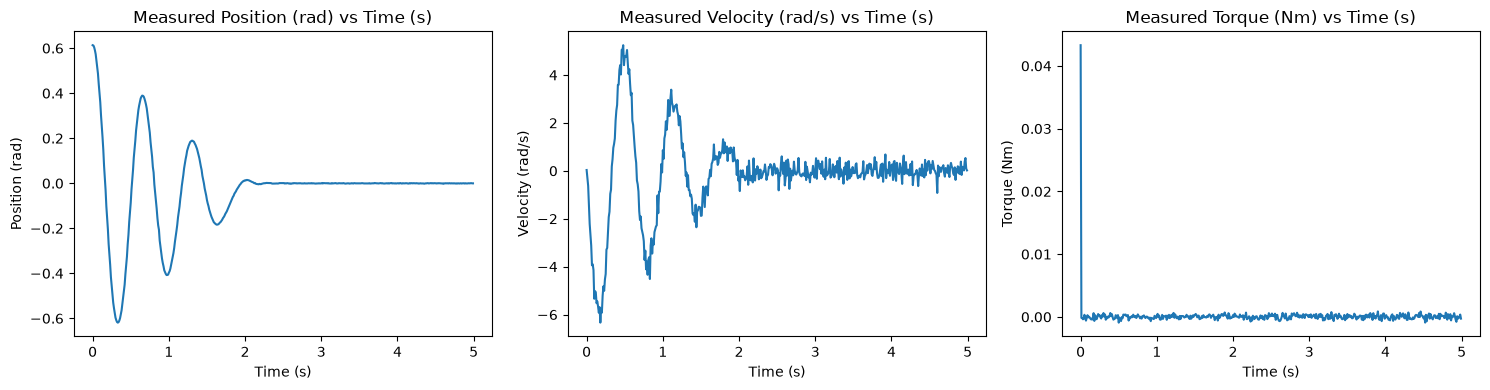

In [5]:
import math
import numpy as np
import matplotlib.pyplot as plt

Tf = 5.0
session_token, livestream_url = client.start_experiment(
    user_token = user_token,
    experiment_type = "SimplePendulum",
    experiment_time = Tf,
    preparation_time = 5.0,
    initial_position = [np.pi/4],
    record = False
)
print("Received response from server!")
print("Session token: ", session_token)

dt = 0.01
meas_dt = 0.0
meas_time = 0.0

print("Desired dt: ", dt)

n = int(Tf / dt)

# Create data matrices (one row per joint, one column per time step)
meas_time_vec = np.zeros(n)
meas_pos = np.zeros((1, n))
meas_vel = np.zeros((1, n))
meas_tau = np.zeros((1, n))
meas_dt_vec = np.zeros(n)

i = 0

print("Running the control loop")
while meas_time < Tf and i < n:
    start_loop = time.time()
    meas_time += meas_dt

    # Measure data
    measured_position = client.get_position(session_token) # Measure position
    measured_velocity = client.get_velocity(session_token) # Measure velocity
    measured_torque = client.get_torque(session_token) # Measure torque

    # add data to matrices
    meas_time_vec[i] = meas_time
    meas_pos[:, i] = measured_position
    meas_vel[:, i] = measured_velocity    
    meas_tau[:, i] = measured_torque
        
    while time.time() - start_loop < dt:
        pass
        
    meas_dt = time.time() - start_loop
    meas_dt_vec[i] = meas_dt

    i = i + 1
    
print("Finished")
print("Average measured dt: ", np.mean(meas_dt_vec))

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(meas_time_vec, meas_pos.T)
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(meas_time_vec, meas_vel.T)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(meas_time_vec, meas_tau.T)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.set_title("Measured Torque (Nm) vs Time (s)")

plt.tight_layout()
plt.show()

For a nicer plot, we can clean up our data:

Number of missed control ticks:  0


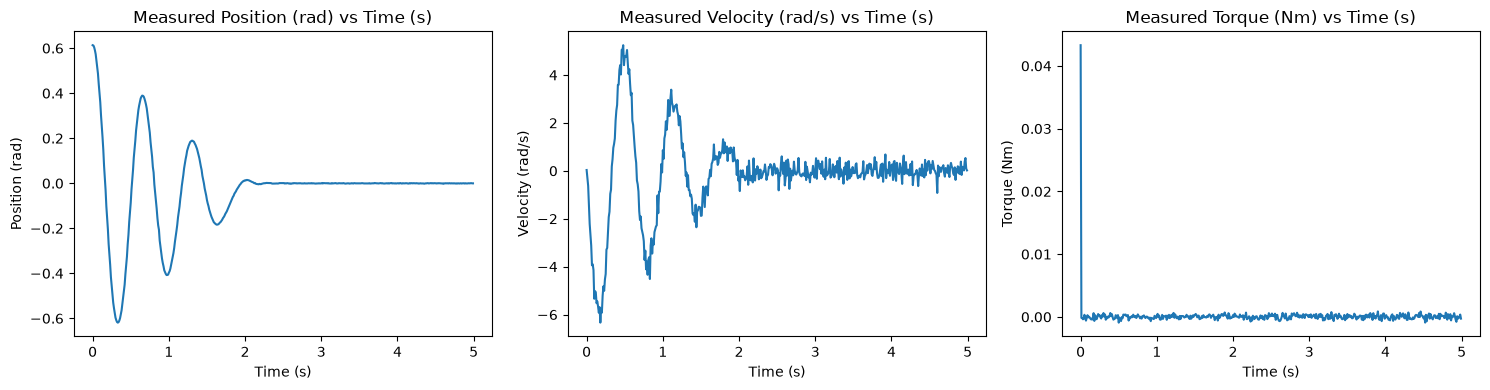

In [6]:
# Data cleanup for plotting because sometimes a few control ticks maybe missed 
lastnonzero_index = np.max(np.nonzero(meas_time_vec)[-1]) + 1
N = int(Tf/dt)
print("Number of missed control ticks: ", N - lastnonzero_index)
meas_time_vec = meas_time_vec[:lastnonzero_index]
meas_pos = meas_pos[:, :lastnonzero_index]
meas_vel = meas_vel[:, :lastnonzero_index]
meas_tau = meas_tau[:, :lastnonzero_index]

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(meas_time_vec, meas_pos.T)
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(meas_time_vec, meas_vel.T)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(meas_time_vec, meas_tau.T)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.set_title("Measured Torque (Nm) vs Time (s)")

plt.tight_layout()
plt.show()

In general, it is hard to get exact timing on standard operating systems. In our case, we do not have a real-time OS at hand, but we can at least tune our computer. One way of achieving better real-time performance is e.g. the following workaround:

In [7]:
def wait_for_control_loop_end(start_loop, dt):
        """Delay ending a while loop so that it loops at a desired sampling time dt."""
        time_to_pass = start_loop + dt - time.time()
        if time_to_pass <= 0.0:
            return
        
        time.sleep(time_to_pass * 0.7) # sleep
        while time.time() - start_loop < dt: # busy waiting
            pass

In future experiments, we use this method for better accuracy in timing. At this point, we do not discuss the how/why in detail, but feel free to check the detailed analysis later in this tutorial.

## 2.2. Controlling the motor

Now that we have reserved a cell from the server and read the data, let's do what we are here for: Let's control the motor! The controller that the API provides us is an impendance controller. The following excerpt from the documentation of the hardware describes its functionality very well:

From [MAB documentation](https://mabrobotics.github.io/MD80-x-CANdle-Documentation/MD/motion.html#impedance-pd):

"Impedance Control mode is a popular choice for mobile or legged robots, as well as for any compliant mechanism. The main idea behind it is to mimic the behavior of a torsional spring with variable stiffness and damping. The parameters of the controller are:
- Position Target
- Velocity Target
- kP (position gain)
- kD (velocity gain)
- Torque Feed Forward (Torque FF)

The torque output is proportional to the position error and velocity error and additionally supplemented with a torque command from the user."


The impedance controller operates at a frequency of 40 kHz, allowing the motors to quickly respond to any disturbances. Most of the time, however, we will use our own controllers, which output a torque as a response to the state of the system. This can be easily done by setting both kP and kD to zero and using the output of our controller as feed forward torque. The impedance controller is relatively simple and works according to the schematic below:

<div>
<img src="media/impedance_controller.png" width="800"/>
</div>

The controller can therefore be written as follows, and allows for a mixture of different applications:
$$u = K_p (\theta - \theta^*) + K_d (\dot{\theta} - \dot{\theta}^*) + \theta \tag{1},$$
where $\theta$ is the angle and $\dot{\theta}$ is the angular velocity.

### 2.2.1. Position control

The motors are by default started in impedance control mode with proportional gain Kp and derivative gain Kd set to zero i.e. pure torque control. In this example we use `set_position` to set the position of the motor directly. We set only $K_p$ and $K_d$, and a setpoint for the position. In this case, the impendance controller becomes a simple PD controller for the position.

Later, we will use `set_velocity` or `set_torque` to set the velocity and torque of the motor respectively.

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=2258982264224859392
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Received response from server!
Session token:  2258982264224859392
Livestream url:  http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=2258982264224859392
Desired dt:  0.01
Running the control loop
Finished
Average measured dt:  0.010009103899548767


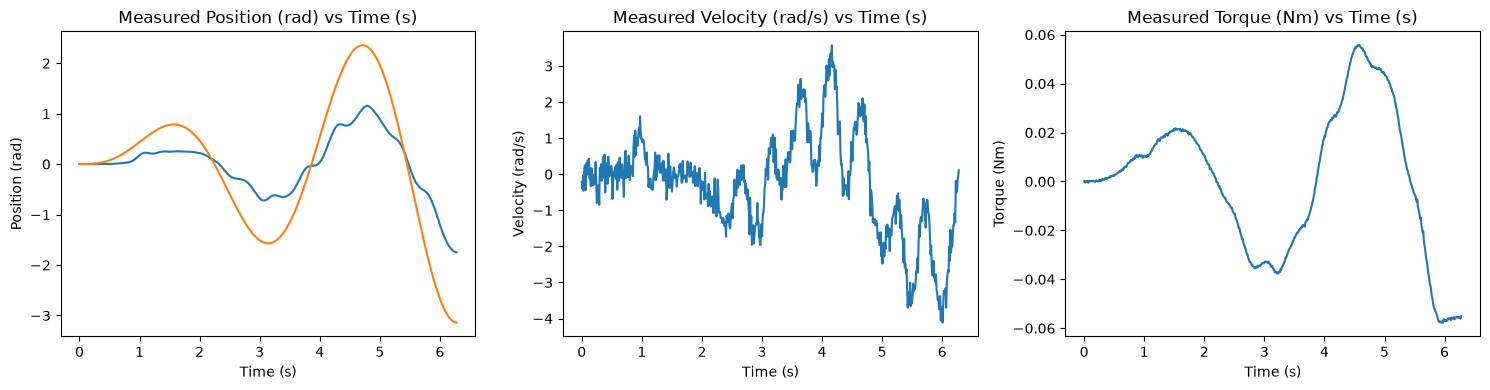

Conversion successful: videos/225898226422485939220261120-030850-PM.mp4


In [8]:
import math
import numpy as np
import matplotlib.pyplot as plt

Tf = 2 * math.pi
client = Client()
session_token, livestream_url = client.start_experiment(
    user_token = user_token,
    experiment_type = "SimplePendulum",
    experiment_time = Tf,
    preparation_time = 5.0,
    initial_position = [0.0],
    record = True
)
print("Received response from server!")
print("Session token: ", session_token)
print("Livestream url: ", livestream_url)

# Set Kp, Kd for position control
kp = 0.075
kd = 0.0
client.set_impedance_controller_params([kp], [kd], session_token)

dt = 0.01
meas_dt = 0.0
meas_time = 0.0

print("Desired dt: ", dt)

n = int(Tf / dt)

meas_time_vec = np.zeros(n)
meas_pos = np.zeros((1, n))
meas_vel = np.zeros((1, n))
meas_tau = np.zeros((1, n))
meas_dt_vec = np.zeros(n)
des_pos = np.zeros((1, n))

i = 0

print("Running the control loop")
while meas_time < Tf and i < n:
    start_loop = time.time()
    meas_time += meas_dt

    # Measure data
    measured_position = client.get_position(session_token) # Measure position
    measured_velocity = client.get_velocity(session_token) # Measure velocity
    measured_torque = client.get_torque(session_token) # Measure torque

    # Send position command
    des_pos[:, i] = math.sin(2*meas_time)/4.0 - meas_time*math.cos(2*meas_time)/2.0
    client.set_position(des_pos[:, i], session_token)

    # Collect data for plotting
    meas_time_vec[i] = meas_time
    meas_pos[:, i] = measured_position
    meas_vel[:, i] = measured_velocity    
    meas_tau[:, i] = measured_torque
        
    wait_for_control_loop_end(start_loop, dt)
    
    meas_dt = time.time() - start_loop
    meas_dt_vec[i] = meas_dt

    i = i + 1
    
print("Finished")

video_url = client.stop_experiment(session_token)
time.sleep(1.0)

print("Average measured dt: ", np.mean(meas_dt_vec))

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(meas_time_vec, meas_pos.T)
ax1.plot(meas_time_vec, des_pos.T)
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(meas_time_vec, meas_vel.T)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(meas_time_vec, meas_tau.T)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.set_title("Measured Torque (Nm) vs Time (s)")

plt.tight_layout()
plt.show()

if not USE_LOCAL:
    # Show video
    from misc import download_video
    video_path = download_video(video_url)
    from IPython.display import Video
    display(Video(video_path, embed=True))

**Remark:** The position tracking is not perfect. By selecting better Kp and Kd values this can be improved.

### 2.2.2. Velocity control

Next, we control the velocity $\dot{\theta}$ instead of the position $\theta$, and set a desired velocity $\dot{\theta}^*$. To only control the velocity, we disable the part controlling the position by setting $K_p=0$, and choose a desired $K_d$, essentially resulting in a P-controller for the velocity.

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=1456288271519376128
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Received response from server!
Session token:  1456288271519376128
Desired dt:  0.01
Running the control loop
Finished
Average measured dt:  0.010006016731262207


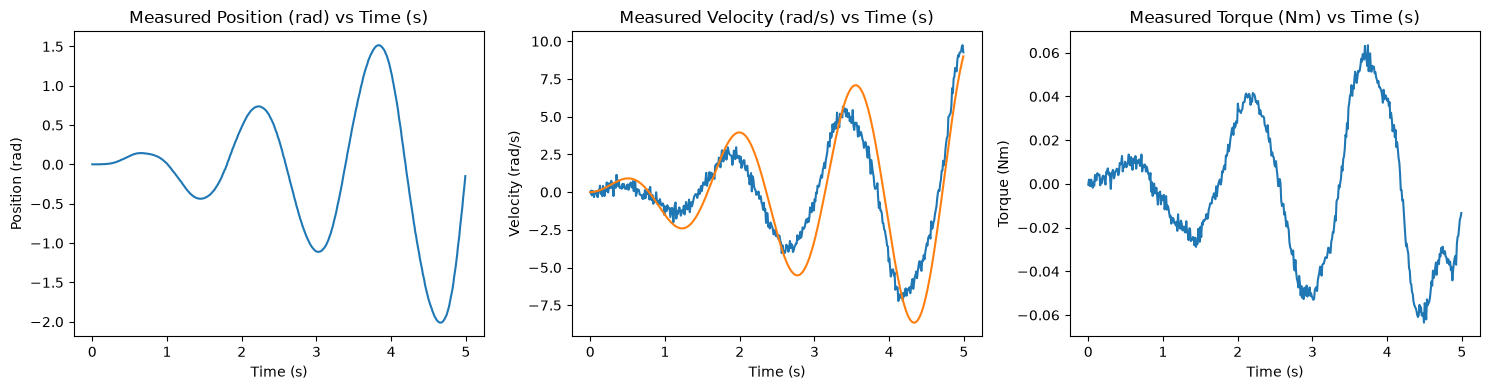

Conversion successful: videos/145628827151937612820261120-030908-PM.mp4


In [9]:
Tf = 5.0
client = Client()
session_token, livestream_url = client.start_experiment(
    user_token = user_token,
    experiment_type = "SimplePendulum",
    experiment_time = Tf,
    preparation_time = 5.0,
    record = True
)
print("Received response from server!")
print("Session token: ", session_token)

# Set Kp, Kd for velocity control
kp = 0.0
kd = 0.02
client.set_impedance_controller_params([kp], [kd], session_token)

dt = 0.01
meas_dt = 0.0
meas_time = 0.0

print("Desired dt: ", dt)

n = int(Tf / dt)

meas_time_vec = np.zeros(n)
meas_pos = np.zeros((1, n))
meas_vel = np.zeros((1, n))
meas_tau = np.zeros((1, n))
meas_dt_vec = np.zeros(n)
des_vel = np.zeros((1, n))

i = 0

print("Running the control loop")
while meas_time < Tf and i < n:
    start_loop = time.time()
    meas_time += meas_dt

    # Measure data
    measured_position = client.get_position(session_token) # Measure position
    measured_velocity = client.get_velocity(session_token) # Measure velocity
    measured_torque = client.get_torque(session_token) # Measure torque

    # Send velocity command
    des_vel[:, i] = 2*meas_time*math.sin(meas_time*4)
    client.set_velocity(des_vel[:, i], session_token)

    # Collect data for plotting
    meas_time_vec[i] = meas_time
    meas_pos[:, i] = measured_position
    meas_vel[:, i] = measured_velocity    
    meas_tau[:, i] = measured_torque

    wait_for_control_loop_end(start_loop, dt)

    meas_dt = time.time() - start_loop
    meas_dt_vec[i] = meas_dt
    
    i = i + 1

print("Finished")

video_url = client.stop_experiment(session_token)
time.sleep(1.0)

print("Average measured dt: ", np.mean(meas_dt_vec))

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(meas_time_vec, meas_pos.T)
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(meas_time_vec, meas_vel.T)
ax2.plot(meas_time_vec, des_vel.T)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(meas_time_vec, meas_tau.T)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.set_title("Measured Torque (Nm) vs Time (s)")

plt.tight_layout()
plt.show()

if not USE_LOCAL:
    # Show video
    from misc import download_video
    video_path = download_video(video_url)
    from IPython.display import Video
    display(Video(video_path, embed=True))

### 2.2.3. Torque control

In the last example, direct control of the torque is demonstrated. As you can see from eq. (1), the torque command is a direct feed forward. Thus, we set both $K_p = K_d = 0$, and use `set_torque` to set the torque.

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=1154115962365436416
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Received response from server!
Session token:  1154115962365436416
Livestream url:  http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=1154115962365436416
Desired dt:  0.01
Running the control loop
Finished
Average measured dt:  0.010006321083967852


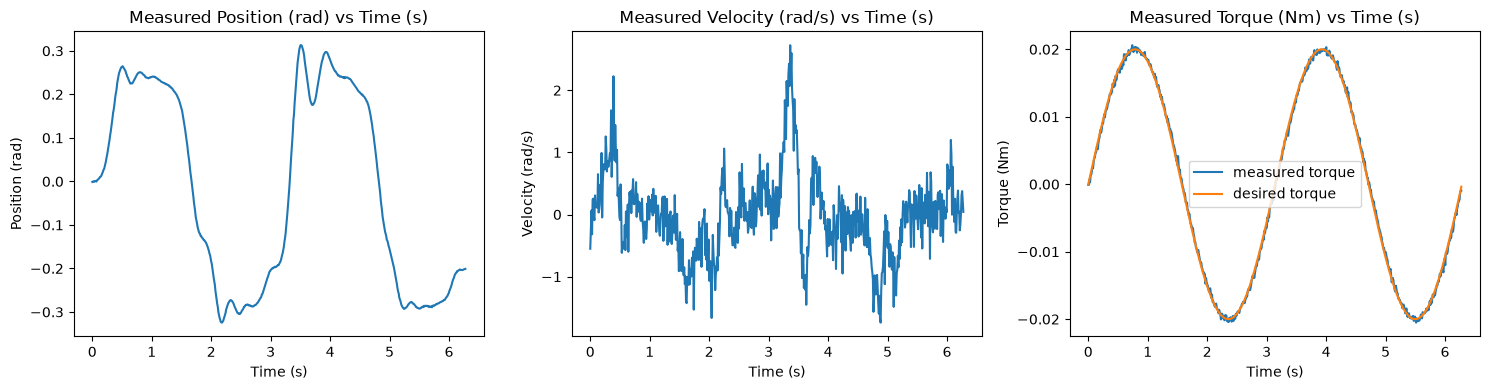

Conversion successful: videos/115411596236543641620261120-030924-PM.mp4


In [10]:
Tf = 2*math.pi
client = Client()
session_token, livestream_url = client.start_experiment(
    user_token = user_token,
    experiment_type = "SimplePendulum",
    experiment_time = Tf,
    preparation_time = 5.0,
    record = True
)
print("Received response from server!")
print("Session token: ", session_token)
print("Livestream url: ", livestream_url)

# Set Kp, Kd for torque control
kp = 0.0
kd = 0.0
client.set_impedance_controller_params([kp], [kd], session_token)

dt = 0.01
meas_dt = 0.0
meas_time = 0.0

print("Desired dt: ", dt)

n = int(Tf / dt)

meas_time_vec = np.zeros(n)
meas_pos = np.zeros((1, n))
meas_vel = np.zeros((1, n))
meas_tau = np.zeros((1, n))
meas_dt_vec = np.zeros(n)
des_tau = np.zeros((1, n))

i = 0

print("Running the control loop")
while meas_time < Tf and i < n:
    start_loop = time.time()
    meas_time += meas_dt

    # Measure data
    measured_position = client.get_position(session_token) # Measure position
    measured_velocity = client.get_velocity(session_token) # Measure velocity
    measured_torque = client.get_torque(session_token) # Measure torque

    # Send position command
    des_tau[:, i] = 0.02*np.sin(2*meas_time)
    client.set_torque(des_tau[:, i], session_token)

    # Collect data for plotting
    meas_time_vec[i] = meas_time
    meas_pos[:, i] = measured_position
    meas_vel[:, i] = measured_velocity    
    meas_tau[:, i] = measured_torque
        
    wait_for_control_loop_end(start_loop, dt)
    
    meas_dt = time.time() - start_loop
    meas_dt_vec[i] = meas_dt

    i = i + 1
    
print("Finished")

video_url = client.stop_experiment(session_token)
time.sleep(1.0)

print("Average measured dt: ", np.mean(meas_dt_vec))

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(meas_time_vec, meas_pos.T)
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(meas_time_vec, meas_vel.T)
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(meas_time_vec, meas_tau.T)
ax3.plot(meas_time_vec, des_tau.T)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.legend(["measured torque", "desired torque"])
ax3.set_title("Measured Torque (Nm) vs Time (s)")

plt.tight_layout()
plt.show()

if not USE_LOCAL:
    # Show video
    from misc import download_video
    video_path = download_video(video_url)
    from IPython.display import Video
    display(Video(video_path, embed=True))

## 3. Using PendulumPlant

To streamline the process of interacting with the cells of cloud pendulum, we provide a class containing a simulator, visualization tools, and a simple way of running experiments. We will use this toolset in some tutorials, in which it will be described in more depth. For now, we present an abridged introduction.

## 3.1. Example: No controller test

Before implementing our own controller, let's test the simulator and hardware experiment methods.

The first step in setting up our instance of _PendulumPlant_ is to import the class. We define the physical properties of our pendulum and instantiate the class.

In [11]:
import numpy as np
from IPython.display import HTML
from pendulum_plant import PendulumPlant, plot_timeseries
import matplotlib.pyplot as plt

mass = 0.06                    # mass at the end of the pendulum [kg]
length = 0.1                   # length of the rod [m]
damping = 0.0                  # viscious friction [kg m/s]
gravity = 9.81                 # gravity [kg m/s²]
inertia = mass*length*length   # inertia of the pendulum [kg m²]
torque_limit = np.inf          # torque limit of the motor, here we assume the motor can produce any torque [Nm]

pendulum = PendulumPlant(mass=mass,
                        length=length,
                        damping=damping,
                        gravity=gravity,
                        inertia=inertia,
                        torque_limit=torque_limit)

First, we will test the simulator by dropping the pendulum from an initial position of $\theta$ = $\frac{\pi}{4}$

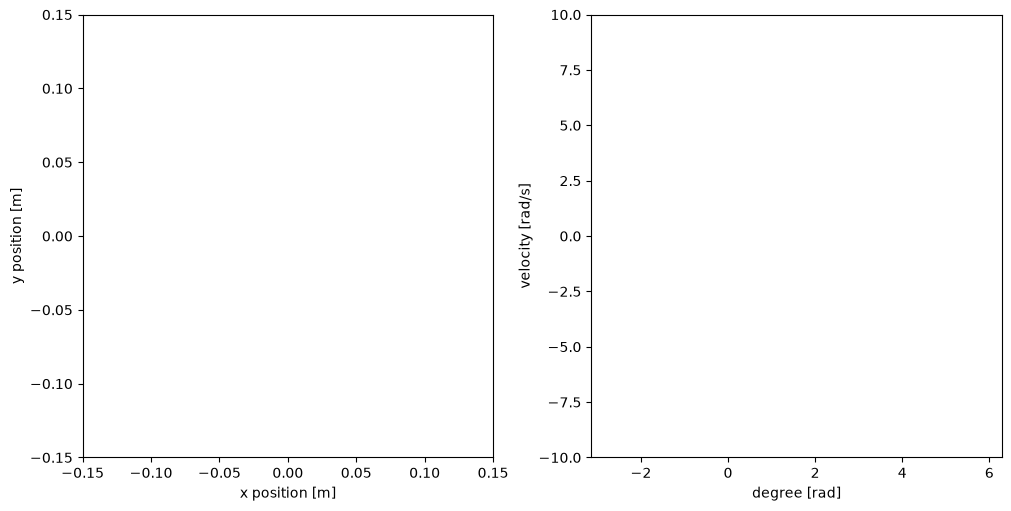

In [12]:
Tsim_euler, Xsim_euler, Usim_euler, anim_euler = pendulum.simulate_and_animate(
              t0=0.0,
              x0=[np.pi/4, 0.0],
              tf=5.0,
              dt=0.002,
              controller=None,
              integrator="runge_kutta", anim_dt = 0.04)

Run the following cell to see an animation of the motion.

In [13]:
HTML(anim_euler.to_html5_video())

Now, let's try to run the same experiment on the hardware in the our lab. To do so, we will use the _run_on_hardware_ function.

Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=959626571587358208
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Conversion successful: videos/95962657158735820820261120-031002-PM.mp4


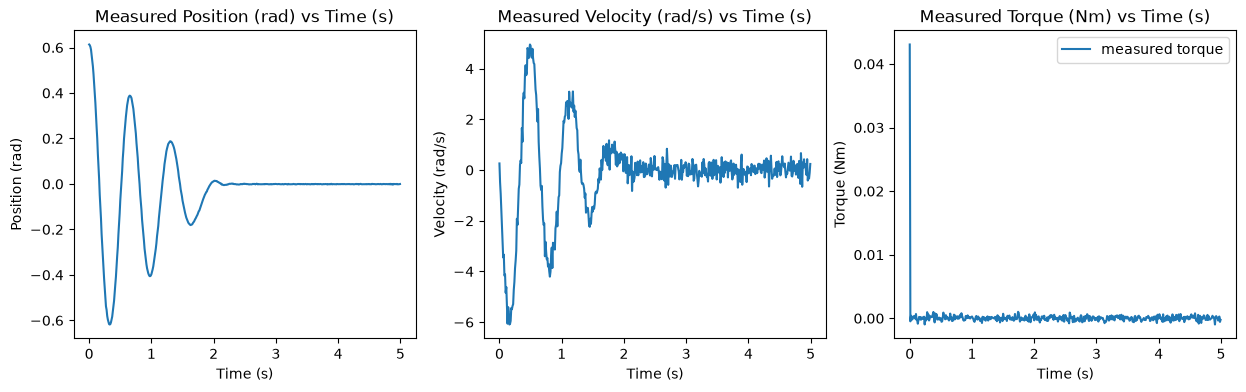

In [14]:
from IPython.display import Video
tf = 10 # Final time (s)
dt = 0.01 # Time step (s)
Treal_ff, Xreal_ff, Ureal_ff, Ureal_des, exp_video_url, exp_video_path = pendulum.run_on_hardware_cloud(user_token=user_token,
                                                                            tf=5.0,
                                                                            dt=0.01, 
                                                                            x0=np.pi/4, 
                                                                            controller=None,
                                                                            save_video=False if USE_LOCAL else True) 

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(Treal_ff, np.asarray(Xreal_ff).T[0])
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(Treal_ff, np.asarray(Xreal_ff).T[1])
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(Treal_ff, Ureal_ff)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.legend(["measured torque", "desired torque"])
ax3.set_title("Measured Torque (Nm) vs Time (s)")
plt.show()

# Export the data to csv file
measured_csv_data = np.array([Treal_ff, np.asarray(Xreal_ff).T[0], np.asarray(Xreal_ff).T[1],Ureal_ff]).T
np.savetxt("ff_measured_data.csv", measured_csv_data, delimiter=',', header="time,pos,vel,tau", comments="")
if not USE_LOCAL:
    display(Video(exp_video_path, embed=True))

## 3.2. Example: Implementing a PID

Now that we have tested the simulator and hardware, let's implement a controller!

A very common and simple controller is the Proportional-Integral-Derivative (PID) controller. It responds to feedback from the observed state and compares it to a setpoint, obtaining the error. This controller has three components:
- The proportional: Reacts to the current error.
- The integral: Reacts to the accumulated error with the goal of eliminating steady-state error.
- The derivative: Reacts to the rate of change of the error to improve stability and reduce oscillations.

The controller is tuned by adjusting the coefficients $K_p$, $K_i$, and $K_d$. The control input of the controller ($u$) can be described as follows:

\begin{equation}
u(t) = K_p e(t) + K_i \int e(t) dt + K_p \frac{d e(t)}{dt}
\end{equation}

where $e(t)$ is the error.

The following is a template for a PID controller compatible with _PendulumPlant_.

In [15]:
class PIDController():
    def __init__(self, torque_limit, Kp, Ki, Kd, dt):
        print("torque_limit: ", torque_limit)
        
        self.Kp = Kp
        self.Ki = Ki
        self.Kd = Kd
        self.torque_limit = torque_limit
        
        self.dt = dt        
        self.errors = []

    def set_goal(self, goal=[np.pi, 0.0]):
        self.goal = goal

    def reset_controller(self):
        self.errors = []

    def get_control_output(self, x):
        # Extract current state variables
        theta = x[0]  # current angle of the pendulum

        # Compute the error
        error = self.goal[0] - theta

        # Store the current error for the next iteration
        self.errors.append(error)

        # Compute the integral of the error
        integral = np.sum(self.errors) * self.dt

        # Compute the derivative of the error
        if len(self.errors) > 1:
            derivative = (self.errors[-1] - self.errors[-2]) / self.dt
        else:
            derivative = 0.0

        # Compute the control output
        tau = self.Kp * error + self.Ki * integral + self.Kd * derivative # PID version
        tau = np.clip(tau,-self.torque_limit, self.torque_limit)
        
        return tau

## Think-Pair-Share (5 min)

- Tune the PID controller by adjusting the values of _pid_controller.Kp_, _pid_controller.Ki_, and _pid_controller.Kd_ in the next cell and test it in the simulator. Try to minimize the settling time and overshoot.

torque_limit:  0.15


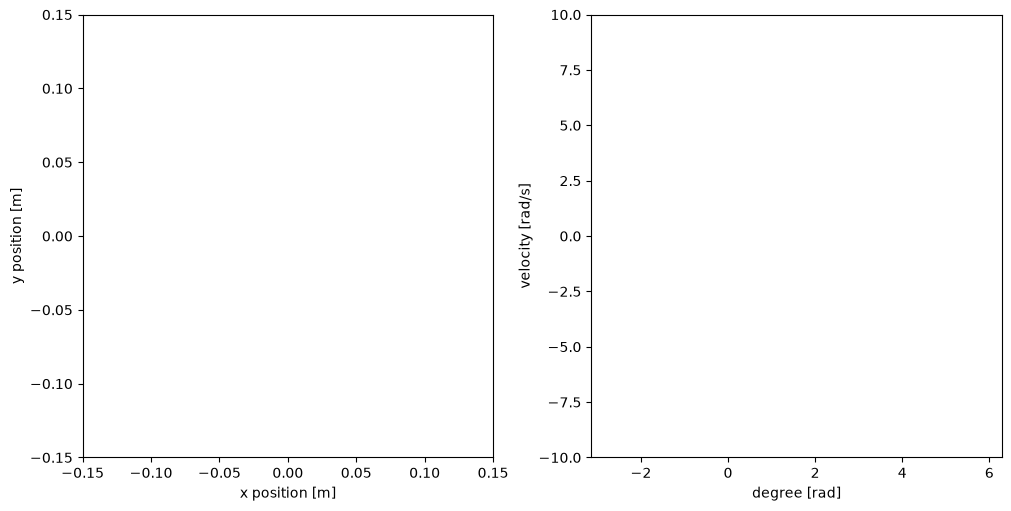

In [16]:
pid_controller = PIDController(torque_limit=0.15,
                               Kp=0.1,
                               Ki=0.0,
                               Kd=0.01,
                               dt=0.01)

pid_controller.set_goal(goal=[np.pi, 0.0])

Tsim_PID, Xsim_PID, Usim_PID, anim_PID = pendulum.simulate_and_animate(
              t0=0.0,
              x0=[0.0, 0.0],
              tf=5.0,
              dt=0.002,
              controller=pid_controller,
              integrator="runge_kutta", anim_dt = 0.04)

Run the following cell to generate the animation of the simulation.

In [17]:
HTML(anim_PID.to_html5_video())

And the next cell to produce the plots.

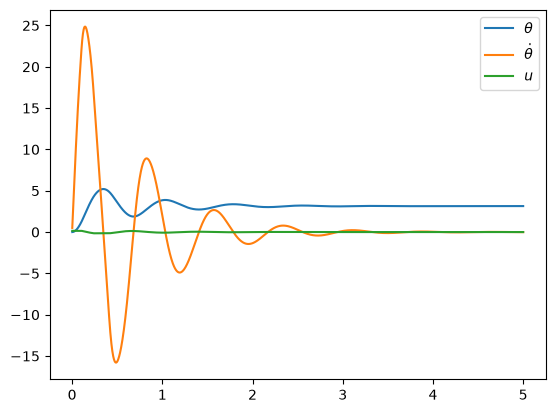

In [18]:
plot_timeseries(Tsim_PID, Xsim_PID, Usim_PID)

## Think-Pair-Share (5 min)

Now that we know that our PID works, we can test it out on the real hardware.

- Run the experiment cell below. Try to tune the controller again to optimize its performance. Does the system respond differently to the simulation?

torque_limit:  0.13
Successfully initialized connection to the server
Livestream url: http://cloudpendulum.m2.chalmers.se:5080/live/viewer.jsp?host=cloudpendulum.m2.chalmers.se&stream=36844511323290880
Starting in 5 seconds
Starting in 4 seconds
Starting in 3 seconds
Starting in 2 seconds
Starting in 1 seconds
Starting
Conversion successful: videos/3684451132329088020261120-031224-PM.mp4


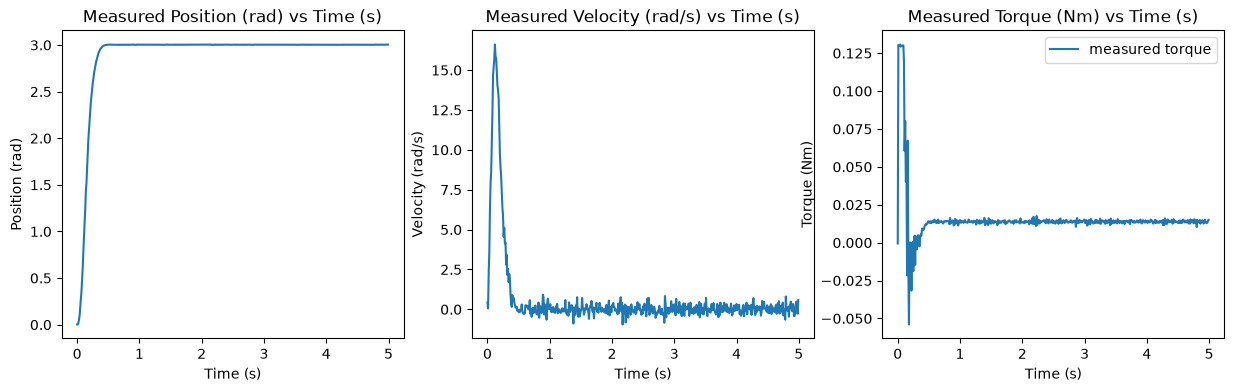

In [21]:
pid_controller_real = PIDController(torque_limit=0.13,
                               Kp=0.1,
                               Ki=0.0,
                               Kd=0.01,
                               dt=0.01)

pid_controller_real.set_goal(goal=[np.pi, 0.0])

tf = 5.0 # Final time (s)
dt = 0.01 # Time step (s)
Treal_pid, Xreal_pid, Ureal_pid, Ureal_pid_des, pid_video_url, pid_video_path = pendulum.run_on_hardware_cloud(user_token=user_token,
                                                                            tf=5.0,
                                                                            dt=0.01, 
                                                                            x0=0.0, 
                                                                            controller=pid_controller_real,
                                                                            save_video=False if USE_LOCAL else True)

# Show plots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

# Measured Position
ax1.plot(Treal_pid, np.asarray(Xreal_pid).T[0])
ax1.set_xlabel("Time (s)") 
ax1.set_ylabel("Position (rad)")
ax1.set_title("Measured Position (rad) vs Time (s)")

# Measured Velocity
ax2.plot(Treal_pid, np.asarray(Xreal_pid).T[1])
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Velocity (rad/s)")
ax2.set_title("Measured Velocity (rad/s) vs Time (s)")

# Measured Torque
ax3.plot(Treal_pid, Ureal_pid)
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Torque (Nm)")
ax3.legend(["measured torque", "desired torque"])
ax3.set_title("Measured Torque (Nm) vs Time (s)")

# Export the data to csv file
measured_csv_data = np.array([Treal_pid, np.asarray(Xreal_pid).T[0], np.asarray(Xreal_pid).T[1],Ureal_pid]).T
np.savetxt("pid_measured_data.csv", measured_csv_data, delimiter=',', header="time,pos,vel,tau", comments="")
if not USE_LOCAL:
    display(Video(pid_video_path, embed=True))